# 01 · ConvNeXt-Tiny: entrenamiento trinario frente a binario

**Pregunta:** ¿Cómo cambia la detección de glaucoma al entrenar con tres clases (`Sano`, `Etapa inicial`, `Avanzado`) frente a entrenar directamente con dos clases (`Sano`, `Positivo`)?

Referencia histórica: [Notebook de Andrés](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración y datos auditados

Se carga el inventario limpio (`dataset_auditado.csv`), sin duplicados internos ni cruces entre `train`, `val`, `test` y cohortes externas (`ACRIMA`, `RIM-ONE DL`, `EyePACS REAL`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision import transforms as T

# Detectar raíz del proyecto e importar utilidades compartidas
_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))

import utilidades as u

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "04_experimento_trinario_vs_binario/resultados"
SALIDAS.mkdir(parents=True, exist_ok=True)
MODELOS = ROOT / "modelos"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Parámetros del experimento
EPOCHS = 20
BATCH_SIZE = 32
REENTRENAR = False  # Pon True si quieres reentrenar desde cero aunque exista el .pth

u.fijar_semilla(u.SEED)
df_datos, df_depuracion = u.cargar_dataset(ROOT)

train_df = df_datos[df_datos["split"] == "train"].reset_index(drop=True)
val_df = df_datos[df_datos["split"] == "val"].reset_index(drop=True)
eval_sets = {"Moondream · test": df_datos[df_datos["split"] == "test"].reset_index(drop=True)}
for fuente in ("ACRIMA", "RIM-ONE DL", "EyePACS REAL"):
    sub = df_datos[df_datos["coleccion"] == fuente].reset_index(drop=True)
    if len(sub):
        eval_sets[fuente] = sub

print(f"Dispositivo: {DEVICE} | Imágenes elegibles totales: {len(df_datos)}")
display(df_datos.groupby(["coleccion", "split", "clase"]).size().rename("n").reset_index())

Dispositivo: cuda | Imágenes elegibles totales: 2056


,coleccion,split,clase,n
0,ACRIMA,externo,glaucoma,395
1,ACRIMA,externo,normal,308
2,EyePACS REAL,externo,glaucoma,100
3,EyePACS REAL,externo,normal,100
4,Moondream Staged,test,advanced,25
5,Moondream Staged,test,early,21
6,Moondream Staged,test,normal,49
7,Moondream Staged,train,advanced,125
8,Moondream Staged,train,early,115
9,Moondream Staged,train,normal,264


## 2. Control de atajo de color (RGB medio)

Verificamos cuánto clasifica una regresión logística entrenada únicamente con el color promedio `(R, G, B)` de la imagen frente a predecir la clase mayoritaria en Moondream `test`.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def medir_color_y_relleno(df):
    filas = []
    for ruta in df["id"]:
        pix = np.asarray(u.leer_rgb(ROOT, ruta))
        esquinas = [b.reshape(-1, 3).mean(0) for b in (pix[:4, :4], pix[:4, -4:], pix[-4:, :4], pix[-4:, -4:])]
        r, g, b = pix.mean(axis=(0, 1))
        filas.append({
            "R": r, "G": g, "B": b,
            "pad_negro": int(any(c.max() < 20 for c in esquinas)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in esquinas)),
        })
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(filas)], axis=1)

color_df = medir_color_y_relleno(df_datos)
display(color_df.groupby(["coleccion", "clase"])[["R", "G", "B", "pad_negro", "pad_gris"]].mean().round(2))

tr_c = color_df[color_df["split"] == "train"]
te_c = color_df[color_df["split"] == "test"]
cols_rgb = ["R", "G", "B"]

filas_control = []
for nombre, clf in [("RGB medio", LogisticRegression(max_iter=1000)),
                    ("Clase mayoritaria", DummyClassifier(strategy="most_frequent"))]:
    clf.fit(tr_c[cols_rgb], tr_c["y3"].astype(int))
    pred = clf.predict(te_c[cols_rgb])
    m, _ = u.calcular_metricas(te_c["y3"].to_numpy(int), pred, 3)
    m["exactitud binaria"] = float(np.mean((pred > 0) == te_c["y2"]))
    filas_control.append({"control": nombre, **m})

display(pd.DataFrame(filas_control).round(3))

R       G      B  pad_negro  pad_gris
coleccion        clase                                               
ACRIMA           glaucoma  190.03   86.30  19.95       0.08      0.00
                 normal    178.90  108.16  31.85       0.14      0.00
EyePACS REAL     glaucoma   86.26   55.45  36.69       1.00      0.00
                 normal     89.39   55.60  35.74       1.00      0.00
Moondream Staged advanced  164.68  102.59  47.85       0.45      0.17
                 early     160.05  101.09  53.98       0.49      0.20
                 normal    162.36  110.28  70.59       0.53      0.14
RIM-ONE DL       glaucoma  147.05   69.16  37.62       0.04      0.00
                 normal    150.42   64.70  35.69       0.01      0.00

,control,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado,exactitud binaria
0,RGB medio,95,0.382,0.558,0.391,0.857,0.143,0.609,0.0,0.44,0.282,14,14,21,0.632
1,Clase mayoritaria,95,0.227,0.516,0.000,1.000,0.000,1.000,0.0,0.00,0.000,21,25,25,0.516


## 3. Referencia histórica de Andrés

Matriz publicada en el notebook de Andrés sobre su partición de Moondream (`n = 115`, ConvNeXt-Tiny, época 8, umbral $\tau = 0.95$).

,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado
Andrés · referencia (n=115),115,0.722,0.774,0.804,0.932,0.068,0.196,0.519,0.69,0.713,6,5,7


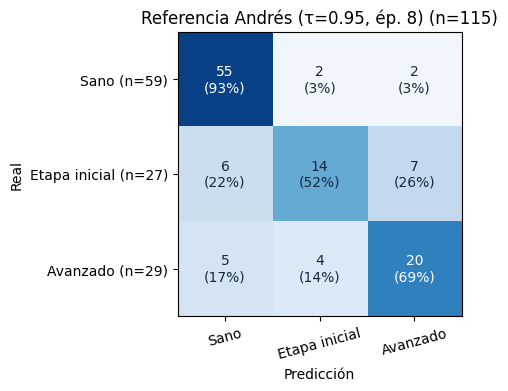

In [3]:
MATRIZ_ANDRES = np.array([[55, 2, 2], [6, 14, 7], [5, 4, 20]])
y_andres, pred_andres = np.repeat(np.indices((3, 3)).reshape(2, -1), MATRIZ_ANDRES.ravel(), axis=1)
metricas_andres, _ = u.calcular_metricas(y_andres, pred_andres, 3)
display(pd.DataFrame([metricas_andres], index=["Andrés · referencia (n=115)"]).round(3))
u.graficar_matrices({"Referencia Andrés (τ=0.95, ép. 8)": MATRIZ_ANDRES}, u.CLASES_3)

## 4. Entrenamiento trinario vs. binario (con la receta de Andrés)

Ambos modelos usan exactamente la misma partición auditada, semilla y aumentos de entrenamiento (`RandomResizedCrop`, volteo horizontal, rotación $\pm 15^\circ$ y `ColorJitter`). La mejor época y el umbral binario $\tau$ (buscando especificidad $\ge 0.95$) se eligen **solo en validación**.

Modelo cargado: fabian_convnext_tiny_3c_andres.pth (mejor época 10)


Modelo 3 clases · ép. 10 · τ=0.81 (espec. val=0.981)


Modelo cargado: fabian_convnext_tiny_2c_andres.pth (mejor época 3)


Modelo 2 clases · ép. 3 · τ=0.90 (espec. val=0.962)


,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,recall inicial,recall avanzado,QWK,FN inicial,FN avanzado,errores sano ↔ avanzado
ConvNeXt 3 clases · Moondream test (auditado),95,0.731,0.789,0.935,0.898,0.102,0.065,0.476,0.84,0.801,3,0,3


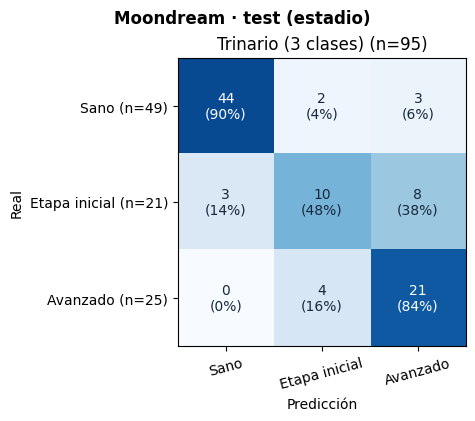

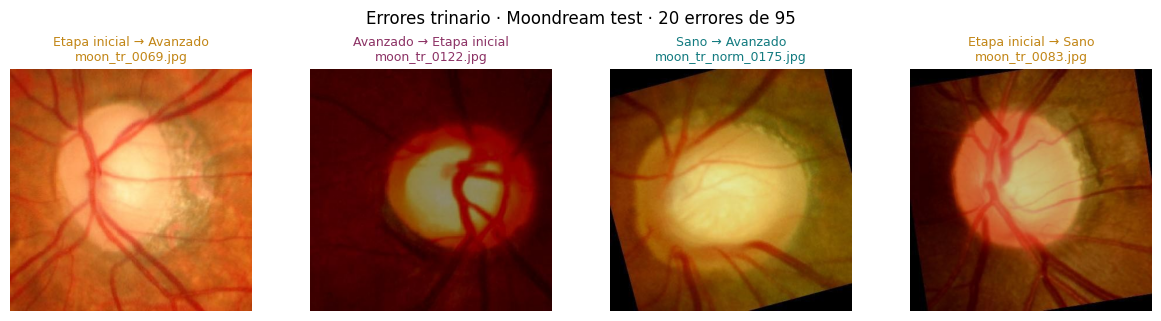

In [4]:
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(u.MEAN, u.STD)])
tf_train = T.Compose([
    T.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.03),
    T.ToTensor(),
    T.Normalize(u.MEAN, u.STD),
])

corridas = {}
for n_clases in (3, 2):
    ruta_pth = MODELOS / f"fabian_convnext_tiny_{n_clases}c_andres.pth"
    res = u.entrenar_o_cargar(
        train_df, val_df, ROOT, n_clases, tf_train, tf_eval,
        ruta_modelo=ruta_pth, epochs=EPOCHS, batch_size=BATCH_SIZE,
        device=DEVICE, reentrenar=REENTRENAR,
    )
    y_val = val_df[f"y{n_clases}"].to_numpy(int)
    tau, espec = u.calibrar_umbral(y_val, res["val_prob"], n_clases)
    tau_bin, espec_bin = (u.calibrar_umbral(val_df["y2"].to_numpy(int), res["val_prob"], 2)
                          if n_clases == 3 else (tau, espec))

    probs = {}
    for nombre, df_eval in eval_sets.items():
        nivel = n_clases if nombre == "Moondream · test" else 2
        loader = u.crear_loader(df_eval, ROOT, nivel, tf_eval, batch_size=BATCH_SIZE, device=DEVICE)
        _, probs[nombre] = u.predecir(res["model"], loader, DEVICE, calcular_loss=False)

    corridas[n_clases] = {
        "epoca": res["epoca"], "tau": tau, "espec": espec,
        "tau_bin": tau_bin, "espec_bin": espec_bin, "probs": probs,
    }
    print(f"Modelo {n_clases} clases · ép. {res['epoca']} · τ={tau:.2f} (espec. val={espec:.3f})")
    del res["model"]
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# Evaluación de estadio (3 clases) en Moondream test
df_test_moon = eval_sets["Moondream · test"]
y3_test = df_test_moon["y3"].to_numpy(int)
pred3_test = u.decidir_con_umbral(corridas[3]["probs"]["Moondream · test"], corridas[3]["tau"])
met3, cm3 = u.calcular_metricas(y3_test, pred3_test, 3)
display(pd.DataFrame([met3], index=["ConvNeXt 3 clases · Moondream test (auditado)"]).round(3))
u.graficar_matrices({"Trinario (3 clases)": cm3}, u.CLASES_3, "Moondream · test (estadio)")
u.mostrar_errores(df_test_moon, y3_test, pred3_test, u.CLASES_3, ROOT, "Errores trinario · Moondream test")

## 5. Detección binaria en todas las cohortes

Comparamos:
- **Proyección trinario → binario:** $P(\text{positivo}) = P(\text{Inicial}) + P(\text{Avanzado})$ con su $\tau$ calibrado en validación.
- **Entrenado binario:** $P(\text{Positivo})$ de la cabeza de 2 clases con su $\tau$ calibrado en validación.

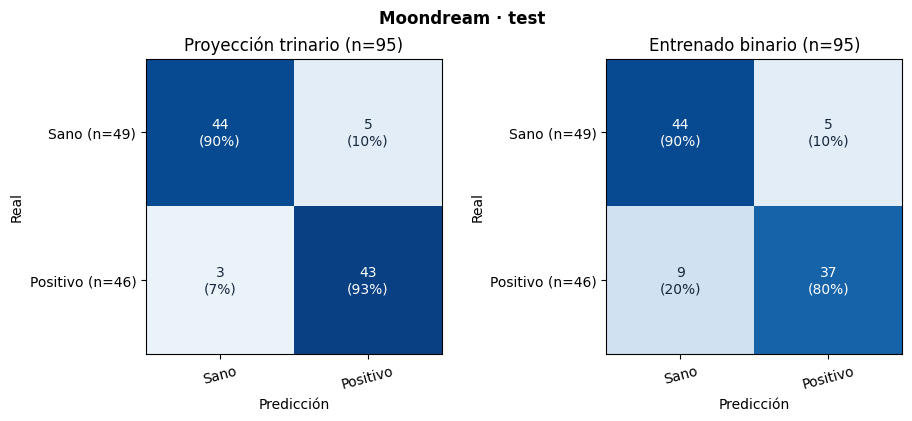

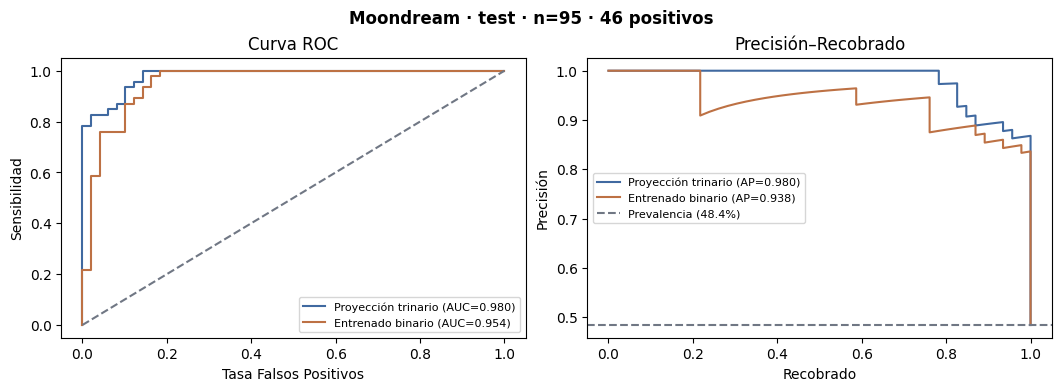

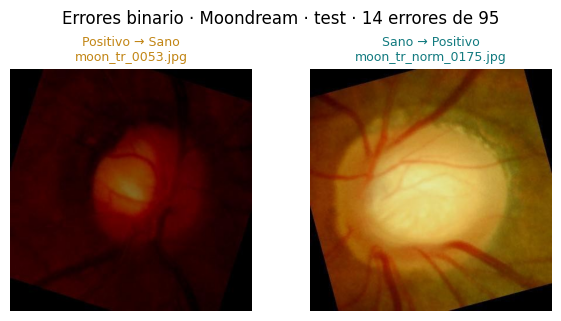

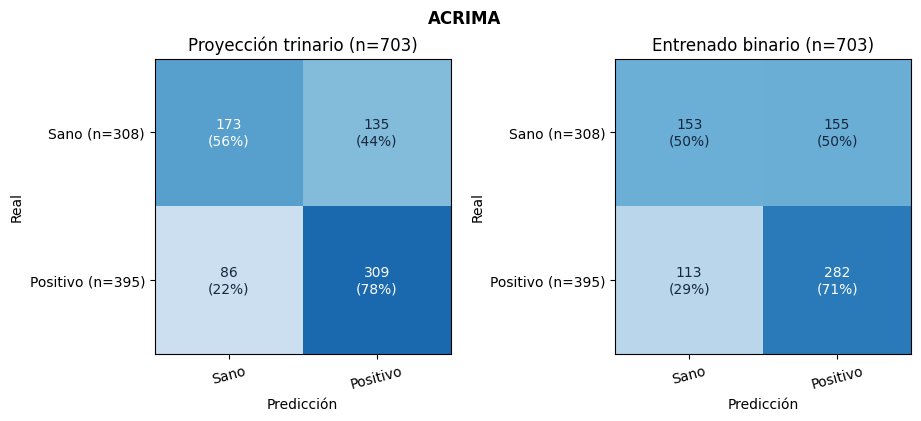

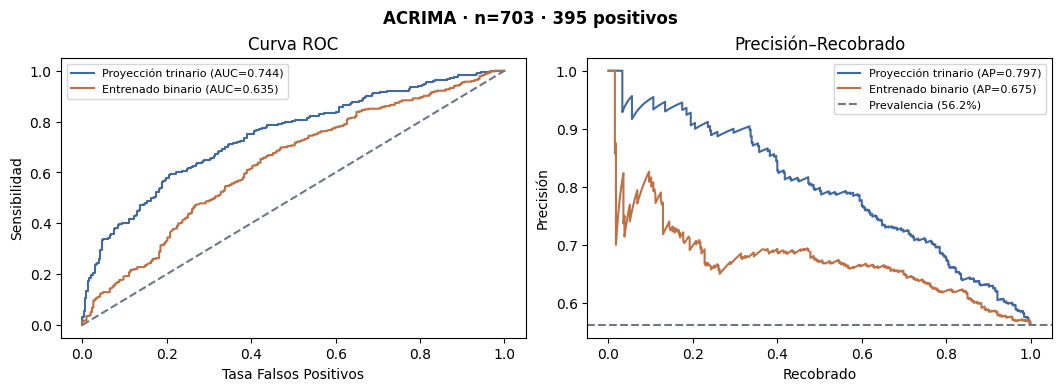

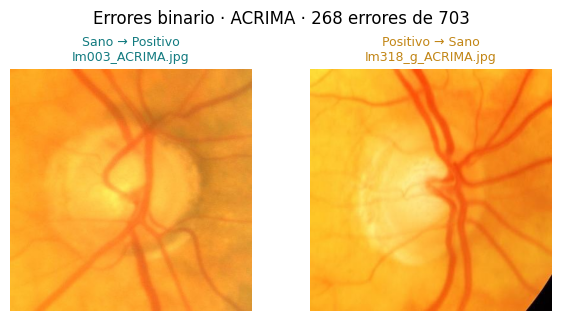

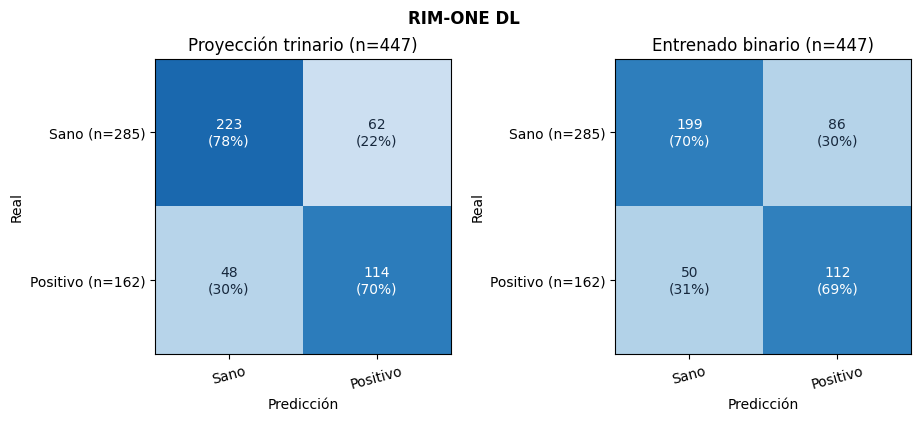

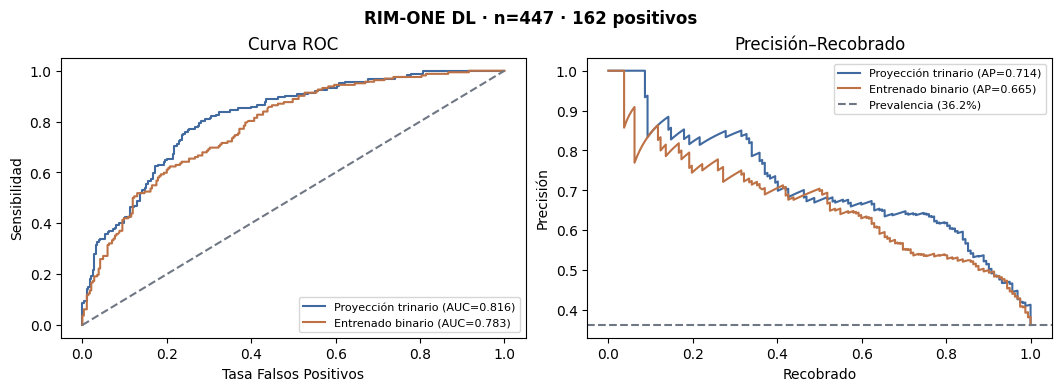

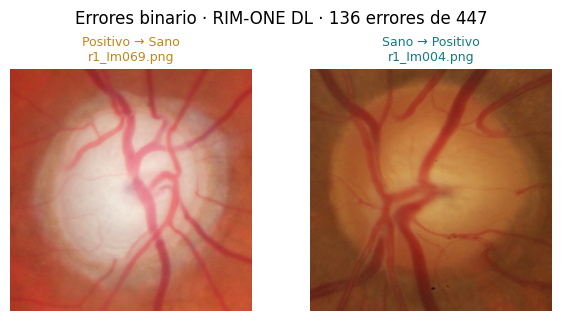

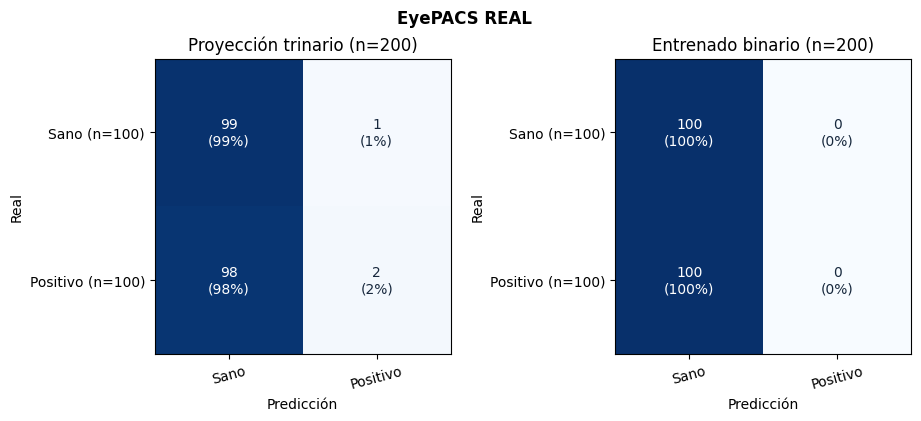

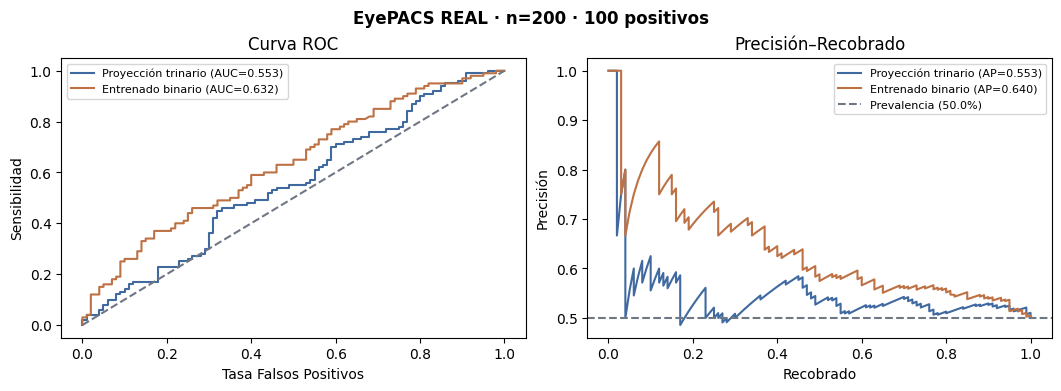

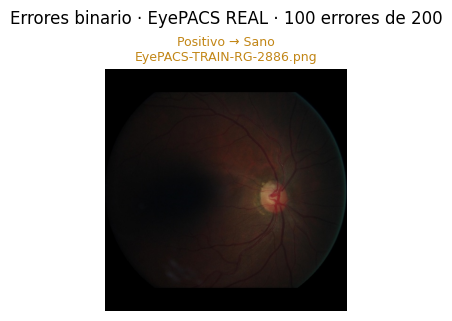

Umbral proyección trinario: τ=0.81 (espec. val=0.981)
Umbral entrenado binario : τ=0.90 (espec. val=0.962)


,cohorte,modelo,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,TFN,FP,FN,AUROC,AP
0,Moondream · test,Proyección trinario,95,0.916,0.916,0.935,0.898,0.102,0.065,5,3,0.980,0.980
1,Moondream · test,Entrenado binario,95,0.852,0.853,0.804,0.898,0.102,0.196,5,9,0.954,0.938
2,ACRIMA,Proyección trinario,703,0.673,0.686,0.782,0.562,0.438,0.218,135,86,0.744,0.797
3,ACRIMA,Entrenado binario,703,0.605,0.619,0.714,0.497,0.503,0.286,155,113,0.635,0.675
4,RIM-ONE DL,Proyección trinario,447,0.738,0.754,0.704,0.782,0.218,0.296,62,48,0.816,0.714
5,RIM-ONE DL,Entrenado binario,447,0.684,0.696,0.691,0.698,0.302,0.309,86,50,0.783,0.665
6,EyePACS REAL,Proyección trinario,200,0.353,0.505,0.020,0.990,0.010,0.980,1,98,0.553,0.553
7,EyePACS REAL,Entrenado binario,200,0.333,0.500,0.000,1.000,0.000,1.000,0,100,0.632,0.640


Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap:


,medida,delta,ic95_inf,ic95_sup,cohorte,n
0,F1 macro,-0.064,-0.141,0.010,Moondream · test,95
1,sensibilidad,-0.130,-0.240,-0.022,Moondream · test,95
2,especificidad,0.000,-0.102,0.102,Moondream · test,95
3,F1 macro,-0.068,-0.096,-0.037,ACRIMA,703
4,sensibilidad,-0.068,-0.106,-0.033,ACRIMA,703
5,especificidad,-0.065,-0.110,-0.019,ACRIMA,703
6,F1 macro,-0.055,-0.097,-0.018,RIM-ONE DL,447
7,sensibilidad,-0.012,-0.080,0.056,RIM-ONE DL,447
8,especificidad,-0.084,-0.130,-0.039,RIM-ONE DL,447
9,F1 macro,-0.019,-0.052,0.004,EyePACS REAL,200


Moondream · test (n=95) · Δ F1=-6.4 pp · Δ Sens=-13.0 pp · Δ Espec=+0.0 pp
ACRIMA (n=703) · Δ F1=-6.8 pp · Δ Sens=-6.8 pp · Δ Espec=-6.5 pp
RIM-ONE DL (n=447) · Δ F1=-5.5 pp · Δ Sens=-1.2 pp · Δ Espec=-8.4 pp
EyePACS REAL (n=200) · Δ F1=-1.9 pp · Δ Sens=-2.0 pp · Δ Espec=+1.0 pp


In [5]:
registros, intervalos, predicciones_out = [], [], []

for fuente, df_eval in eval_sets.items():
    y2 = df_eval["y2"].to_numpy(int)
    scores, decisiones, panel = {}, {}, {}

    for n_clases, etiqueta in ((3, "Proyección trinario"), (2, "Entrenado binario")):
        prob = corridas[n_clases]["probs"][fuente]
        sc = u.p_positivo(prob)
        pred = (sc >= corridas[n_clases]["tau_bin"]).astype(int)
        scores[etiqueta] = sc
        decisiones[etiqueta] = pred
        stats, cm = u.calcular_metricas(y2, pred, 2, score_binario=sc)
        registros.append({"cohorte": fuente, "modelo": etiqueta, **stats})
        panel[etiqueta] = cm
        predicciones_out.append(df_eval[["id", "clase", "grupo", "y2"]].assign(
            cohorte=fuente, modelo=etiqueta, pred=pred, prob=sc
        ))

    u.graficar_matrices(panel, u.CLASES_2, fuente)
    u.graficar_curvas_binarias(y2, scores, fuente)
    u.mostrar_errores(df_eval, y2, decisiones["Entrenado binario"], u.CLASES_2, ROOT, f"Errores binario · {fuente}")

    ic = u.bootstrap_diferencia(y2, decisiones["Proyección trinario"], decisiones["Entrenado binario"], 2)
    if len(ic):
        intervalos.append(ic.assign(cohorte=fuente, n=len(df_eval)))

resumen_bin = pd.DataFrame(registros)
resumen_bin.to_csv(SALIDAS / "01_metricas_binarias.csv", index=False)
pd.concat(predicciones_out, ignore_index=True).to_csv(SALIDAS / "01_predicciones_binarias.csv", index=False)

print(f"Umbral proyección trinario: τ={corridas[3]['tau_bin']:.2f} (espec. val={corridas[3]['espec_bin']:.3f})")
print(f"Umbral entrenado binario : τ={corridas[2]['tau_bin']:.2f} (espec. val={corridas[2]['espec_bin']:.3f})")
display(resumen_bin.round(3))

if intervalos:
    print("Diferencia pareada (Entrenado binario − Proyección trinario) con IC 95% bootstrap:")
    display(pd.concat(intervalos, ignore_index=True).round(3))

for fuente, grp in resumen_bin.groupby("cohorte", sort=False):
    p = grp.set_index("modelo")
    diff = p.loc["Entrenado binario", ["F1 macro", "sensibilidad", "especificidad"]] - \
           p.loc["Proyección trinario", ["F1 macro", "sensibilidad", "especificidad"]]
    print(f"{fuente} (n={int(p.iloc[0].n)}) · Δ F1={100*diff['F1 macro']:+.1f} pp · "
          f"Δ Sens={100*diff.sensibilidad:+.1f} pp · Δ Espec={100*diff.especificidad:+.1f} pp")

## 6. Limitaciones

- Las fuentes externas (`ACRIMA`, `RIM-ONE DL`, `EyePACS REAL`) solo tienen etiquetas binarias (`normal` / `glaucoma`), por lo que no permiten evaluar el estadio (`Etapa inicial` vs. `Avanzado`).
- El umbral $\tau$ calibrado en Moondream puede perder sensibilidad al trasladarse a otras cámaras o encuadres (cambio de dominio).